Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving training_set_balanced.csv to training_set_balanced.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving validation_set.csv to validation_set.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving test_set.csv to test_set.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving single_obfuscation_attacks.csv to single_obfuscation_attacks.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving multi_obfuscation_attacks.csv to multi_obfuscation_attacks.csv


In [ ]:
train_df = pd.read_csv("training_set_balanced.csv")
val_df = pd.read_csv("validation_set.csv")
test_df = pd.read_csv("test_set.csv")

single_df = pd.read_csv("single_obfuscation_attacks.csv")
multi_df = pd.read_csv("multi_obfuscation_attacks.csv")

Inspect the data

In [ ]:
print("TRAIN")
print(train_df.shape)
print(train_df.columns)
display(train_df.head())

print("\nVALIDATION")
print(val_df.shape)
print(val_df.columns)

print("\nCLEAN TEST")
print(test_df.shape)
print(test_df.columns)

print("\nSINGLE OBFUSCATION")
print(single_df.shape)
print(single_df.columns)

print("\nMULTI OBFUSCATION")
print(multi_df.shape)
print(multi_df.columns)

TRAIN
(65307, 5)
Index(['id', 'text', 'text_length', 'source_dataset', 'abusive'], dtype='object')


,id,text,text_length,source_dataset,abusive
0,jigsaw_66648,Yes. Also mentioned by New Scientist here:www...,156,JIGSAW,NOT
1,jigsaw_192268,== Requested move == \n\n \n\n :2014 South Ko...,190,JIGSAW,NOT
2,jigsaw_42128,What THE FUCK? \n\nRestore the Code lyoko 2 Ar...,126,JIGSAW,OFF
3,hatexplain_10483,<user> fuck you and your anti white blood libel,47,HateXplain,OFF
4,jigsaw_61369,pure bullshit. The Dissident Aggressor,38,JIGSAW,OFF



VALIDATION
(22771, 5)
Index(['id', 'text', 'text_length', 'source_dataset', 'abusive'], dtype='object')

CLEAN TEST
(22777, 5)
Index(['id', 'text', 'text_length', 'source_dataset', 'abusive'], dtype='object')

SINGLE OBFUSCATION
(42749, 10)
Index(['id', 'text', 'text_length', 'source_dataset', 'abusive',
       'original_text', 'obfuscated_text', 'obfuscation_type', 'severity',
       'obfuscated_length'],
      dtype='object')

MULTI OBFUSCATION
(7872, 11)
Index(['id', 'text', 'text_length', 'source_dataset', 'abusive',
       'original_text', 'obfuscated_text', 'obfuscation_type', 'attack_count',
       'severity', 'obfuscated_length'],
      dtype='object')


In [ ]:
TEXT_COL = "text"
LABEL_COL = "abusive"

Check labels

In [ ]:
print(train_df[LABEL_COL].value_counts())
print(train_df[LABEL_COL].value_counts(normalize=True))

abusive
NOT    43538
OFF    21769
Name: count, dtype: int64
abusive
NOT    0.666667
OFF    0.333333
Name: proportion, dtype: float64


Remove missing data

In [ ]:
train_df = train_df.dropna(subset=[TEXT_COL, LABEL_COL]).copy()
val_df = val_df.dropna(subset=[TEXT_COL, LABEL_COL]).copy()
test_df = test_df.dropna(subset=[TEXT_COL, LABEL_COL]).copy()

train_df[TEXT_COL] = train_df[TEXT_COL].astype(str)
val_df[TEXT_COL] = val_df[TEXT_COL].astype(str)
test_df[TEXT_COL] = test_df[TEXT_COL].astype(str)

Convert off/not into 1/0

In [ ]:
label_map = {
    "NOT": 0,
    "OFF": 1
}

y_train = train_df[LABEL_COL].map(label_map)
y_val = val_df[LABEL_COL].map(label_map)
y_test = test_df[LABEL_COL].map(label_map)

print(y_train.value_counts())

abusive
0    43538
1    21769
Name: count, dtype: int64


In [ ]:
assert y_train.isna().sum() == 0, "Unexpected training labels found."
assert y_val.isna().sum() == 0, "Unexpected validation labels found."
assert y_test.isna().sum() == 0, "Unexpected test labels found."

Character TF-IDF features

In [ ]:
tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    lowercase=True,
    min_df=2,
    max_features=100000,
    sublinear_tf=True
)

In [ ]:
X_train = tfidf.fit_transform(train_df[TEXT_COL])

X_val = tfidf.transform(val_df[TEXT_COL])
X_test = tfidf.transform(test_df[TEXT_COL])

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Test matrix:", X_test.shape)

Training matrix: (65307, 100000)
Validation matrix: (22771, 100000)
Test matrix: (22777, 100000)


Train logistic regression

In [ ]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    solver="liblinear"
)

lr_model.fit(X_train, y_train)

print("Logistic Regression trained.")

Logistic Regression trained.


In [ ]:
class_weight="balanced"

Train linear svm

In [ ]:
svm_model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

svm_model.fit(X_train, y_train)

print("Linear SVM trained.")

Linear SVM trained.


Evaluate on validation data

In [ ]:
def evaluate_model(model, X, y, model_name, dataset_name):

    predictions = model.predict(X)

    results = {
        "model": model_name,
        "dataset": dataset_name,
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions, zero_division=0),
        "recall": recall_score(y, predictions, zero_division=0),
        "f1": f1_score(y, predictions, zero_division=0)
    }

    return results

In [ ]:
lr_val = evaluate_model(
    lr_model,
    X_val,
    y_val,
    "Logistic Regression",
    "Validation"
)

svm_val = evaluate_model(
    svm_model,
    X_val,
    y_val,
    "Linear SVM",
    "Validation"
)

pd.DataFrame([lr_val, svm_val])

,model,dataset,accuracy,precision,recall,f1
0,Logistic Regression,Validation,0.841685,0.420940,0.866176,0.566550
1,Linear SVM,Validation,0.850160,0.433793,0.833456,0.570602


evaluate on clean test set

In [ ]:
lr_clean = evaluate_model(
    lr_model,
    X_test,
    y_test,
    "Logistic Regression",
    "Clean"
)

svm_clean = evaluate_model(
    svm_model,
    X_test,
    y_test,
    "Linear SVM",
    "Clean"
)

clean_results = pd.DataFrame([
    lr_clean,
    svm_clean
])

clean_results

,model,dataset,accuracy,precision,recall,f1
0,Logistic Regression,Clean,0.842385,0.421737,0.857877,0.565481
1,Linear SVM,Clean,0.850375,0.433353,0.817848,0.566523


classification report

In [ ]:
#logistic
lr_predictions = lr_model.predict(X_test)

print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=["NOT", "OFF"]
    )
)

              precision    recall  f1-score   support

         NOT       0.98      0.84      0.90     20054
         OFF       0.42      0.86      0.57      2723

    accuracy                           0.84     22777
   macro avg       0.70      0.85      0.73     22777
weighted avg       0.91      0.84      0.86     22777



In [ ]:
#svm
svm_predictions = svm_model.predict(X_test)

print(
    classification_report(
        y_test,
        svm_predictions,
        target_names=["NOT", "OFF"]
    )
)

              precision    recall  f1-score   support

         NOT       0.97      0.85      0.91     20054
         OFF       0.43      0.82      0.57      2723

    accuracy                           0.85     22777
   macro avg       0.70      0.84      0.74     22777
weighted avg       0.91      0.85      0.87     22777



prepare obfuscated data

In [ ]:
print(single_df.columns.tolist())
print(multi_df.columns.tolist())

['id', 'text', 'text_length', 'source_dataset', 'abusive', 'original_text', 'obfuscated_text', 'obfuscation_type', 'severity', 'obfuscated_length']
['id', 'text', 'text_length', 'source_dataset', 'abusive', 'original_text', 'obfuscated_text', 'obfuscation_type', 'attack_count', 'severity', 'obfuscated_length']


In [ ]:
OBFUSCATED_TEXT_COL = "obfuscated_text"

In [ ]:
print(single_df[LABEL_COL].value_counts())
print(multi_df[LABEL_COL].value_counts())

abusive
OFF    42749
Name: count, dtype: int64
abusive
OFF    7872
Name: count, dtype: int64


In [ ]:
single_df["label_numeric"] = single_df[LABEL_COL].map(label_map)
multi_df["label_numeric"] = multi_df[LABEL_COL].map(label_map)

In [ ]:
#transform obfuscated text
X_single = tfidf.transform(
    single_df[OBFUSCATED_TEXT_COL].astype(str)
)

X_multi = tfidf.transform(
    multi_df[OBFUSCATED_TEXT_COL].astype(str)
)

y_single = single_df["label_numeric"]
y_multi = multi_df["label_numeric"]

In [ ]:
results = []

# Clean
results.append(
    evaluate_model(
        lr_model,
        X_test,
        y_test,
        "Logistic Regression",
        "Clean"
    )
)

results.append(
    evaluate_model(
        svm_model,
        X_test,
        y_test,
        "Linear SVM",
        "Clean"
    )
)

# Single attacks
results.append(
    evaluate_model(
        lr_model,
        X_single,
        y_single,
        "Logistic Regression",
        "Single Obfuscation"
    )
)

results.append(
    evaluate_model(
        svm_model,
        X_single,
        y_single,
        "Linear SVM",
        "Single Obfuscation"
    )
)

# Multi attacks
results.append(
    evaluate_model(
        lr_model,
        X_multi,
        y_multi,
        "Logistic Regression",
        "Multi Obfuscation"
    )
)

results.append(
    evaluate_model(
        svm_model,
        X_multi,
        y_multi,
        "Linear SVM",
        "Multi Obfuscation"
    )
)

results_df = pd.DataFrame(results)

results_df

,model,dataset,accuracy,precision,recall,f1
0,Logistic Regression,Clean,0.842385,0.421737,0.857877,0.565481
1,Linear SVM,Clean,0.850375,0.433353,0.817848,0.566523
2,Logistic Regression,Single Obfuscation,0.679338,1.000000,0.679338,0.809054
3,Linear SVM,Single Obfuscation,0.661302,1.000000,0.661302,0.796125
4,Logistic Regression,Multi Obfuscation,0.495173,1.000000,0.495173,0.662362
5,Linear SVM,Multi Obfuscation,0.523120,1.000000,0.523120,0.686906


robustness drop (performance degradation)

In [ ]:
clean_f1 = {
    "Logistic Regression": lr_clean["f1"],
    "Linear SVM": svm_clean["f1"]
}

results_df["f1_drop"] = results_df.apply(
    lambda row:
    clean_f1[row["model"]] - row["f1"]
    if row["dataset"] != "Clean"
    else 0,
    axis=1
)

results_df

#F1 drop = 0.00 → no degradation

#F1 drop = 0.05 → small degradation

#F1 drop = 0.20 → substantial degradation

,model,dataset,accuracy,precision,recall,f1,f1_drop
0,Logistic Regression,Clean,0.842385,0.421737,0.857877,0.565481,0.000000
1,Linear SVM,Clean,0.850375,0.433353,0.817848,0.566523,0.000000
2,Logistic Regression,Single Obfuscation,0.679338,1.000000,0.679338,0.809054,-0.243574
3,Linear SVM,Single Obfuscation,0.661302,1.000000,0.661302,0.796125,-0.229602
4,Logistic Regression,Multi Obfuscation,0.495173,1.000000,0.495173,0.662362,-0.096881
5,Linear SVM,Multi Obfuscation,0.523120,1.000000,0.523120,0.686906,-0.120383


In [ ]:
print(single_df["obfuscation_type"].value_counts())

obfuscation_type
character_substitution    8169
symbolic_masking          8169
unicode_confusable        8169
misspelling               8154
spacing                   7365
clean                     2723
Name: count, dtype: int64


helper function for grouped attack evaluation

In [ ]:
def evaluate_attack_groups(
    df,
    group_columns,
    model,
    model_name,
    text_column,
    vectorizer,
    clean_f1
):

    rows = []

    for group_values, group_df in df.groupby(group_columns):

        if not isinstance(group_values, tuple):
            group_values = (group_values,)

        X = vectorizer.transform(
            group_df[text_column].astype(str)
        )

        y = group_df["label_numeric"]

        predictions = model.predict(X)

        result = {
            "model": model_name,
            "n_samples": len(group_df),
            "precision": precision_score(
                y, predictions, zero_division=0
            ),
            "recall": recall_score(
                y, predictions, zero_division=0
            ),
            "f1": f1_score(
                y, predictions, zero_division=0
            )
        }

        for column, value in zip(group_columns, group_values):
            result[column] = value

        result["f1_drop"] = clean_f1 - result["f1"]

        rows.append(result)

    return pd.DataFrame(rows)

evaluate single attacks by technique + severity

In [ ]:
lr_single_detail = evaluate_attack_groups(
    single_df,
    ["obfuscation_type", "severity"],
    lr_model,
    "Logistic Regression",
    OBFUSCATED_TEXT_COL,
    tfidf,
    lr_clean["f1"]
)

svm_single_detail = evaluate_attack_groups(
    single_df,
    ["obfuscation_type", "severity"],
    svm_model,
    "Linear SVM",
    OBFUSCATED_TEXT_COL,
    tfidf,
    svm_clean["f1"]
)

single_detailed_results = pd.concat(
    [lr_single_detail, svm_single_detail],
    ignore_index=True
)

display(single_detailed_results)

,model,n_samples,precision,recall,f1,obfuscation_type,severity,f1_drop
0,Logistic Regression,2723,1.0,0.479251,0.647964,character_substitution,high,-0.082484
1,Logistic Regression,2723,1.0,0.803893,0.891287,character_substitution,low,-0.325806
2,Logistic Regression,2723,1.0,0.699596,0.823250,character_substitution,medium,-0.257769
3,Logistic Regression,2723,1.0,0.857877,0.923503,clean,none,-0.358022
4,Logistic Regression,2717,1.0,0.747148,0.855277,misspelling,high,-0.289797
5,Logistic Regression,2719,1.0,0.837072,0.911311,misspelling,low,-0.345831
6,Logistic Regression,2718,1.0,0.803900,0.891291,misspelling,medium,-0.325811
7,Logistic Regression,2307,1.0,0.941916,0.970089,spacing,high,-0.404609
8,Logistic Regression,2585,1.0,0.872340,0.931818,spacing,low,-0.366338
9,Logistic Regression,2473,1.0,0.901334,0.948107,spacing,medium,-0.382627


evaluate severity overall

In [ ]:
lr_severity = evaluate_attack_groups(
    single_df,
    ["severity"],
    lr_model,
    "Logistic Regression",
    OBFUSCATED_TEXT_COL,
    tfidf,
    lr_clean["f1"]
)

svm_severity = evaluate_attack_groups(
    single_df,
    ["severity"],
    svm_model,
    "Linear SVM",
    OBFUSCATED_TEXT_COL,
    tfidf,
    svm_clean["f1"]
)

severity_results = pd.concat(
    [lr_severity, svm_severity],
    ignore_index=True
)

severity_results

,model,n_samples,precision,recall,f1,severity,f1_drop
0,Logistic Regression,13193,1.0,0.539680,0.701029,high,-0.135548
1,Logistic Regression,13473,1.0,0.794181,0.885285,low,-0.319805
2,Logistic Regression,13360,1.0,0.665045,0.798831,medium,-0.233351
3,Logistic Regression,2723,1.0,0.857877,0.923503,none,-0.358022
4,Linear SVM,13193,1.0,0.531797,0.694344,high,-0.127822
5,Linear SVM,13473,1.0,0.758331,0.862558,low,-0.296036
6,Linear SVM,13360,1.0,0.659431,0.794768,medium,-0.228245
7,Linear SVM,2723,1.0,0.817848,0.899798,none,-0.333275


evaluate multi-obfuscation by severity

In [ ]:
lr_multi_detail = evaluate_attack_groups(
    multi_df,
    ["severity"],
    lr_model,
    "Logistic Regression",
    OBFUSCATED_TEXT_COL,
    tfidf,
    lr_clean["f1"]
)

svm_multi_detail = evaluate_attack_groups(
    multi_df,
    ["severity"],
    svm_model,
    "Linear SVM",
    OBFUSCATED_TEXT_COL,
    tfidf,
    svm_clean["f1"]
)

multi_detailed_results = pd.concat(
    [
        lr_multi_detail,
        svm_multi_detail
    ],
    ignore_index=True
)

multi_detailed_results

,model,n_samples,precision,recall,f1,severity,f1_drop
0,Logistic Regression,2572,1.0,0.281104,0.438847,high,0.126634
1,Logistic Regression,2672,1.0,0.712575,0.832168,low,-0.266687
2,Logistic Regression,2628,1.0,0.483638,0.651962,medium,-0.086482
3,Linear SVM,2572,1.0,0.331260,0.497664,high,0.068859
4,Linear SVM,2672,1.0,0.696108,0.820830,low,-0.254307
5,Linear SVM,2628,1.0,0.535008,0.697075,medium,-0.130552


compare clean, single and multi attacks

In [ ]:
comparison = results_df[
    [
        "model",
        "dataset",
        "precision",
        "recall",
        "f1",
        "f1_drop"
    ]
].copy()

comparison.round(4)

,model,dataset,precision,recall,f1,f1_drop
0,Logistic Regression,Clean,0.4217,0.8579,0.5655,0.0000
1,Linear SVM,Clean,0.4334,0.8178,0.5665,0.0000
2,Logistic Regression,Single Obfuscation,1.0000,0.6793,0.8091,-0.2436
3,Linear SVM,Single Obfuscation,1.0000,0.6613,0.7961,-0.2296
4,Logistic Regression,Multi Obfuscation,1.0000,0.4952,0.6624,-0.0969
5,Linear SVM,Multi Obfuscation,1.0000,0.5231,0.6869,-0.1204


plot f1 performance

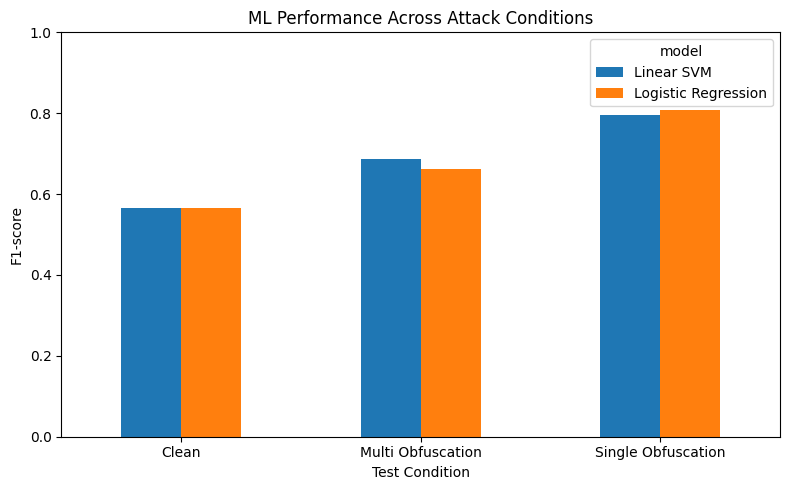

In [ ]:
plot_df = comparison.pivot(
    index="dataset",
    columns="model",
    values="f1"
)

plot_df.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("ML Performance Across Attack Conditions")
plt.ylabel("F1-score")
plt.xlabel("Test Condition")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

plot attack technique robustness

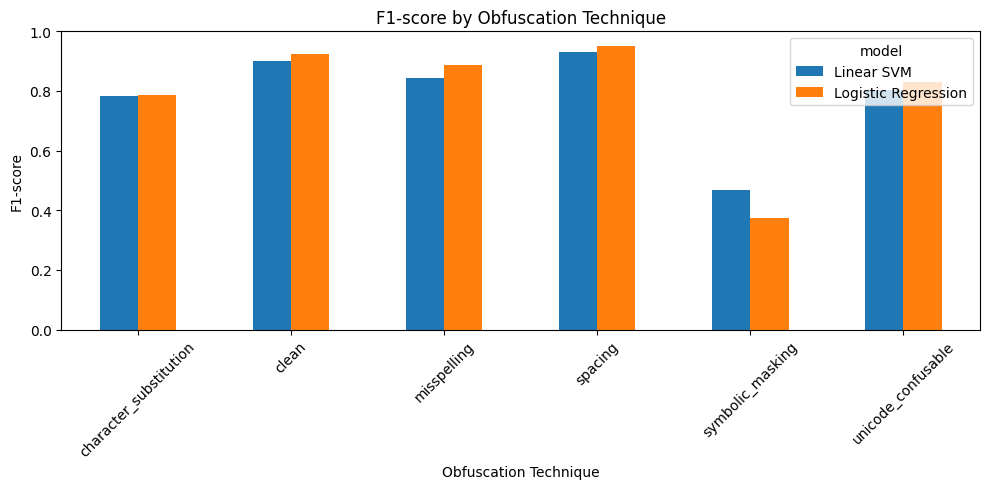

In [ ]:
technique_plot = (
    single_detailed_results
    .groupby(["obfuscation_type", "model"])["f1"]
    .mean()
    .unstack()
)

technique_plot.plot(
    kind="bar",
    figsize=(10,5)
)

plt.ylabel("F1-score")
plt.xlabel("Obfuscation Technique")
plt.title("F1-score by Obfuscation Technique")
plt.ylim(0,1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plot severity

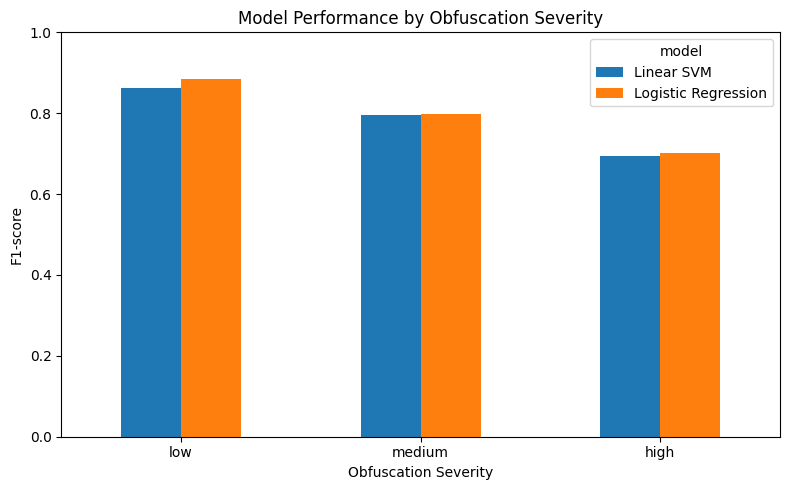

In [ ]:
severity_plot = severity_results.pivot(
    index="severity",
    columns="model",
    values="f1"
)

severity_order = ["low", "medium", "high"]

severity_plot = severity_plot.reindex(
    [x for x in severity_order if x in severity_plot.index]
)

severity_plot.plot(
    kind="bar",
    figsize=(8,5)
)

plt.ylabel("F1-score")
plt.xlabel("Obfuscation Severity")
plt.title("Model Performance by Obfuscation Severity")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

extract false negatives

In [ ]:
#svm
single_df["svm_prediction"] = svm_model.predict(X_single)

svm_false_negatives = single_df[
    (single_df["label_numeric"] == 1) &
    (single_df["svm_prediction"] == 0)
]

print("Number of SVM false negatives:")
print(len(svm_false_negatives))

display(
    svm_false_negatives.head(20)
)

Number of SVM false negatives:
14479


,id,text,text_length,source_dataset,abusive,original_text,obfuscated_text,obfuscation_type,severity,obfuscated_length,label_numeric,svm_prediction
3,jigsaw_88344,Just stating the truth. I know how you people ...,245,JIGSAW,OFF,Just stating the truth. I know how you people ...,Jus7 st@7!ng 7h3 tru7h. I kn0w h0w you p3op13 ...,character_substitution,high,245,1,0
7,jigsaw_88344,Just stating the truth. I know how you people ...,245,JIGSAW,OFF,Just stating the truth. I know how you people ...,.*.. s*a*-n_ *.- trut-. _ .-ow _._ y.. #eop#* ...,symbolic_masking,high,245,1,0
15,hatexplain_9882,maga something has to be done about that scumb...,208,HateXplain,OFF,maga something has to be done about that scumb...,mag@ somethin9 has to be don3 @bout that scumb...,character_substitution,low,208,1,0
17,hatexplain_9882,maga something has to be done about that scumb...,208,HateXplain,OFF,maga something has to be done about that scumb...,ma9@ s0m3thing h@s t0 83 d0ne 480ut 7h@t scum8...,character_substitution,high,208,1,0
20,hatexplain_9882,maga something has to be done about that scumb...,208,HateXplain,OFF,maga something has to be done about that scumb...,maga _-m.thing has to be *on- .bout ..a. scu-b...,symbolic_masking,low,208,1,0
24,hatexplain_9882,maga something has to be done about that scumb...,208,HateXplain,OFF,maga something has to be done about that scumb...,maga smoething has to be done about that scumb...,misspelling,medium,209,1,0
25,hatexplain_9882,maga something has to be done about that scumb...,208,HateXplain,OFF,maga something has to be done about that scumb...,magga something has to be doen abut that spumb...,misspelling,high,207,1,0
26,hatexplain_9882,maga something has to be done about that scumb...,208,HateXplain,OFF,maga something has to be done about that scumb...,maga sоmething has to be done about that sсumb...,unicode_confusable,low,208,1,0
28,hatexplain_9882,maga something has to be done about that scumb...,208,HateXplain,OFF,maga something has to be done about that scumb...,mаgа ѕоmеthing hаѕ tо be dоnе about that ѕcumb...,unicode_confusable,high,208,1,0
32,hatexplain_5589,<user> ‍ daily reminder that nick the spic is ...,99,HateXplain,OFF,<user> ‍ daily reminder that nick the spic is ...,<us3r> ‍ da1ly r3minder 7hat nick 7h3 5pic !$ ...,character_substitution,high,99,1,0


In [ ]:
#logistic
single_df["lr_prediction"] = lr_model.predict(X_single)

lr_false_negatives = single_df[
    (single_df["label_numeric"] == 1) &
    (single_df["lr_prediction"] == 0)
]

display(
    lr_false_negatives.head(20)
)

,id,text,text_length,source_dataset,abusive,original_text,obfuscated_text,obfuscation_type,severity,obfuscated_length,label_numeric,svm_prediction,lr_prediction
6,jigsaw_88344,Just stating the truth. I know how you people ...,245,JIGSAW,OFF,Just stating the truth. I know how you people ...,Ju*t --*__ng t-e tru.h. I k#o. h#w ..u p*op*e ...,symbolic_masking,medium,245,1,1,0
7,jigsaw_88344,Just stating the truth. I know how you people ...,245,JIGSAW,OFF,Just stating the truth. I know how you people ...,.*.. s*a*-n_ *.- trut-. _ .-ow _._ y.. #eop#* ...,symbolic_masking,high,245,1,0,0
17,hatexplain_9882,maga something has to be done about that scumb...,208,HateXplain,OFF,maga something has to be done about that scumb...,ma9@ s0m3thing h@s t0 83 d0ne 480ut 7h@t scum8...,character_substitution,high,208,1,0,0
20,hatexplain_9882,maga something has to be done about that scumb...,208,HateXplain,OFF,maga something has to be done about that scumb...,maga _-m.thing has to be *on- .bout ..a. scu-b...,symbolic_masking,low,208,1,0,0
21,hatexplain_9882,maga something has to be done about that scumb...,208,HateXplain,OFF,maga something has to be done about that scumb...,ma#. _om-t--n# ha* to b- done about that scum....,symbolic_masking,medium,208,1,1,0
22,hatexplain_9882,maga something has to be done about that scumb...,208,HateXplain,OFF,maga something has to be done about that scumb...,mag_ som_t##*g *.. .- .e *#-e a#-ut _h_* .-##....,symbolic_masking,high,208,1,1,0
37,hatexplain_5589,<user> ‍ daily reminder that nick the spic is ...,99,HateXplain,OFF,<user> ‍ daily reminder that nick the spic is ...,<use-> ‍ .ail# r.minde- tha# ni*k the s_i* i# ...,symbolic_masking,medium,99,1,0,0
38,hatexplain_5589,<user> ‍ daily reminder that nick the spic is ...,99,HateXplain,OFF,<user> ‍ daily reminder that nick the spic is ...,<us*#> ‍ d_.ly _emin-e* *ha* _*-- .h# s#ic -* ...,symbolic_masking,high,99,1,0,0
45,jigsaw_70853,"You're a bloody nut,I don't have to ask you fo...",70,JIGSAW,OFF,"You're a bloody nut,I don't have to ask you fo...","You're a bloody nut,I don't have to ask you fo...",clean,none,70,1,0,0
47,jigsaw_70853,"You're a bloody nut,I don't have to ask you fo...",70,JIGSAW,OFF,"You're a bloody nut,I don't have to ask you fo...","You're a b10ody nut,1 don'7 h4ve 7o a5k y0u fo...",character_substitution,medium,70,1,0,0


In [ ]:
comparison.to_csv(
    "ml_overall_results.csv",
    index=False
)

single_detailed_results.to_csv(
    "ml_single_obfuscation_results.csv",
    index=False
)

multi_detailed_results.to_csv(
    "ml_multi_obfuscation_results.csv",
    index=False
)

severity_results.to_csv(
    "ml_severity_results.csv",
    index=False
)

lr_false_negatives.to_csv(
    "lr_false_negatives.csv",
    index=False
)

svm_false_negatives.to_csv(
    "svm_false_negatives.csv",
    index=False
)

print("Results saved.")

Results saved.


In [ ]:
from google.colab import files

files.download("ml_overall_results.csv")
files.download("ml_single_obfuscation_results.csv")
files.download("ml_multi_obfuscation_results.csv")
files.download("ml_severity_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>